#Section C — Menu-Driven Console Mini Capstone

In [3]:
#ANSWER:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------
# Generate Dataset
# --------------------------------------------------

np.random.seed(42)

n = 250

df = pd.DataFrame({
    "restaurant_name": np.random.choice(
        ["Spice Hub", "Urban Bites", "Food Corner", "Tasty Treat", "Royal Kitchen"],
        n
    ),
    "order_value": np.random.uniform(100, 800, n),
    "delivery_time_mins": np.random.normal(30, 8, n),
    "rating": np.random.uniform(1, 5, n),
    "distance_km": np.random.uniform(1, 20, n),
    "discount_pct": np.random.uniform(0, 30, n)
})

# Introduce missing values
df.loc[np.random.choice(df.index, 10, replace=False), "rating"] = np.nan
df.loc[np.random.choice(df.index, 10, replace=False), "delivery_time_mins"] = np.nan

# Fill numeric null values with median
numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].median()
)

print("Dataset Created Successfully")
print("Number of Rows:", len(df))


# --------------------------------------------------
# OPTION 1 - Summary Statistics
# --------------------------------------------------

def summary_statistics():

    print("\n===== SUMMARY STATISTICS =====")

    print(df[numeric_columns].describe())

    print("\nMean Values:")
    print(df[numeric_columns].mean())

    print("\nStandard Deviation:")
    print(df[numeric_columns].std())


# --------------------------------------------------
# OPTION 2 - Distribution Analysis
# --------------------------------------------------

def distribution_analysis():

    plt.figure(figsize=(5, 5))

    sns.histplot(
        df["delivery_time_mins"],
        bins=15,
        kde=True
    )

    plt.title("Delivery Time Distribution")
    plt.xlabel("Delivery Time (Minutes)")
    plt.ylabel("Frequency")

    plt.tight_layout()

    plt.savefig(
        "distribution_analysis.png",
        dpi=150
    )

    plt.close()

    print("\nDistribution chart saved as distribution_analysis.png")


# --------------------------------------------------
# OPTION 3 - Correlation Heatmap
# --------------------------------------------------

def correlation_heatmap():

    correlation = df[numeric_columns].corr()

    plt.figure(figsize=(5, 5))

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")

    plt.tight_layout()

    plt.savefig(
        "correlation_heatmap_section_c.png",
        dpi=150
    )

    plt.close()

    print("\nCorrelation heatmap saved as correlation_heatmap_section_c.png")


# --------------------------------------------------
# OPTION 4 - Restaurant Performance Report
# --------------------------------------------------

def restaurant_performance():

    result = (
        df.groupby("restaurant_name")
        .agg(
            mean_order_value=("order_value", "mean"),
            mean_delivery_time=("delivery_time_mins", "mean"),
            mean_rating=("rating", "mean")
        )
        .sort_values(
            "mean_rating",
            ascending=False
        )
        .reset_index()
    )

    print("\n===== RESTAURANT PERFORMANCE REPORT =====")

    print(result.to_string(index=False))

    # Save performance chart

    plt.figure(figsize=(5, 5))

    plt.bar(
        result["restaurant_name"],
        result["mean_rating"]
    )

    plt.title("Average Restaurant Rating")
    plt.xlabel("Restaurant")
    plt.ylabel("Average Rating")

    plt.xticks(rotation=30)

    plt.tight_layout()

    plt.savefig(
        "restaurant_performance.png",
        dpi=150
    )

    plt.close()

    print("\nRestaurant performance chart saved as restaurant_performance.png")


# --------------------------------------------------
# FINAL SUMMARY
# --------------------------------------------------

def final_summary():

    print("\n======================================")
    print("FINAL DATASET SUMMARY")
    print("======================================")

    # Top 3 restaurants by mean rating

    top_restaurants = (
        df.groupby("restaurant_name")["rating"]
        .mean()
        .sort_values(ascending=False)
        .head(3)
    )

    print("\nTop 3 Restaurants by Mean Rating:")
    print(top_restaurants)

    # Highest absolute Pearson correlation

    corr = df[numeric_columns].corr().abs()

    np.fill_diagonal(corr.values, np.nan)

    max_pair = corr.stack().idxmax()
    max_value = corr.stack().max()

    print("\nHighest Absolute Pearson Correlation:")
    print(max_pair[0], "and", max_pair[1])
    print("Correlation:", round(max_value, 3))

    # Delivery time mean and standard deviation

    print("\nOverall Mean Delivery Time:",
          round(df["delivery_time_mins"].mean(), 2), "minutes")

    print("Overall Standard Deviation:",
          round(df["delivery_time_mins"].std(), 2), "minutes")


# --------------------------------------------------
# MENU
# --------------------------------------------------

while True:

    print("\n")
    print("======================================")
    print(" FOOD DELIVERY DATA ANALYSIS")
    print("======================================")
    print("1. Summary Statistics")
    print("2. Distribution Analysis")
    print("3. Correlation Heatmap")
    print("4. Restaurant Performance Report")
    print("5. Exit")

    choice = input("\nEnter your choice: ")

    if choice == "1":

        summary_statistics()

    elif choice == "2":

        distribution_analysis()

    elif choice == "3":

        correlation_heatmap()

    elif choice == "4":

        restaurant_performance()

    elif choice == "5":

        final_summary()

        print("\nProgram completed successfully.")
        break

    else:

        print("\nInvalid choice. Please enter 1 to 5.")

Dataset Created Successfully
Number of Rows: 250


 FOOD DELIVERY DATA ANALYSIS
1. Summary Statistics
2. Distribution Analysis
3. Correlation Heatmap
4. Restaurant Performance Report
5. Exit

Enter your choice: 1

===== SUMMARY STATISTICS =====
       order_value  delivery_time_mins      rating  distance_km  discount_pct
count   250.000000          250.000000  250.000000   250.000000    250.000000
mean    453.416515           30.609435    3.087025    10.415546     15.399624
std     202.140219            8.608386    1.091330     5.787061      8.145088
min     103.629404            2.174646    1.009358     1.004513      0.270912
25%     282.521011           25.047071    2.258410     5.350664      9.522740
50%     447.409526           31.134848    3.128235    10.236358     16.234043
75%     614.982024           35.698302    4.017152    15.648083     21.740737
max     797.151869           50.933600    4.954915    19.987716     29.800108

Mean Values:
order_value           453.416515
delive

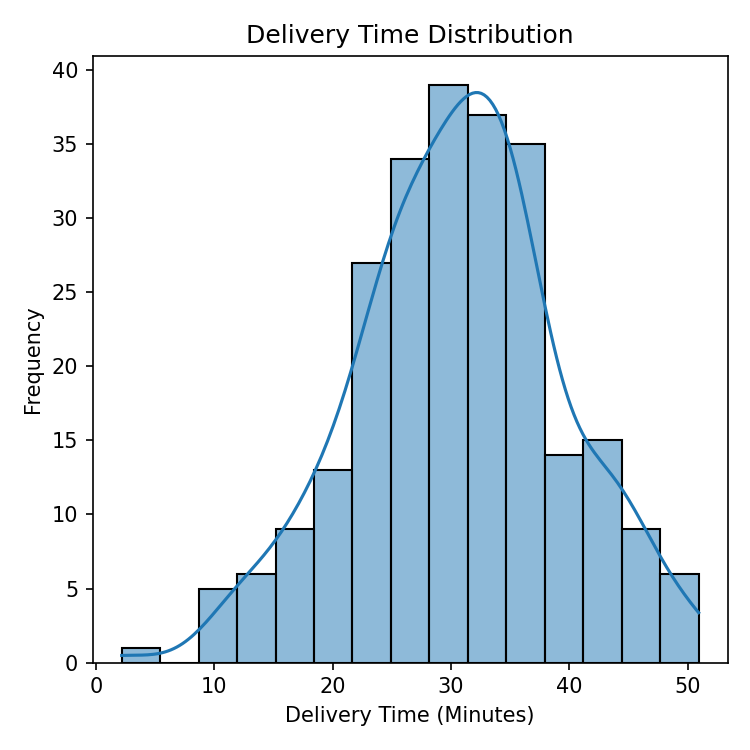

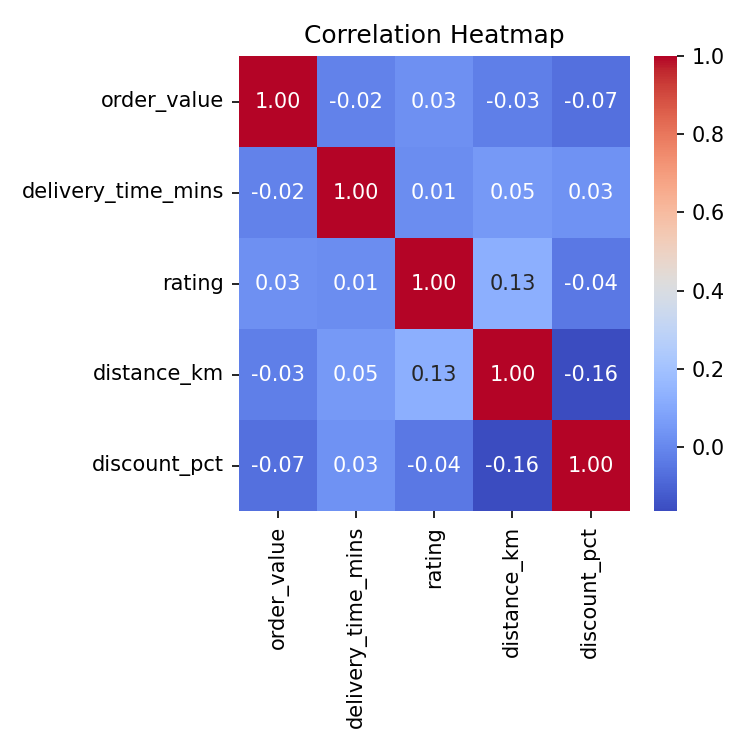

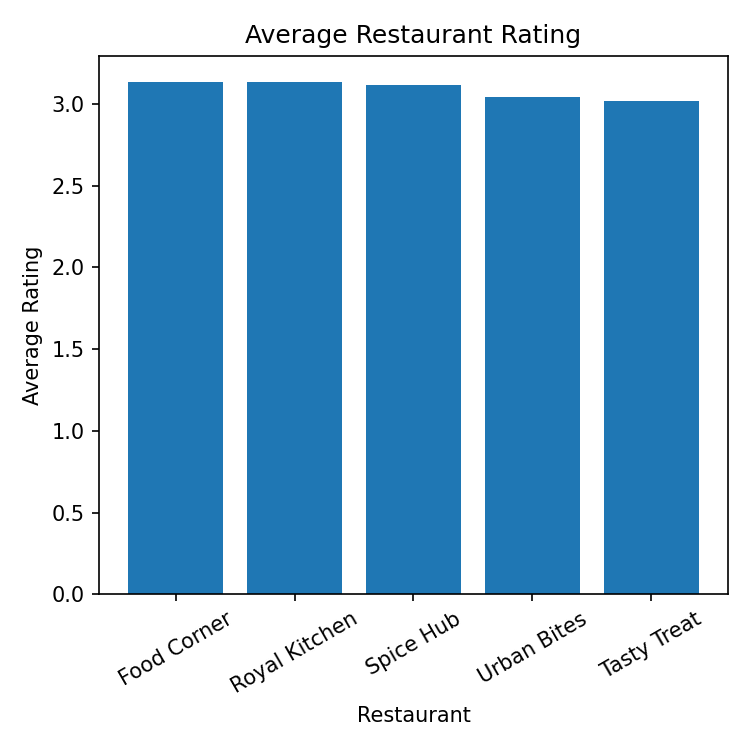

In [4]:
from IPython.display import Image, display

display(Image(filename="distribution_analysis.png"))
display(Image(filename="correlation_heatmap_section_c.png"))
display(Image(filename="restaurant_performance.png"))